# EDA y limpieza del maestro de clientes — Hijos de León (Cundinamarca y Boyacá)

**Proyecto:** balanceo del rutero de preventa (Bavaria / Hijos de León)
**Fuente:** `baseplan22Marzo.xlsx`
**Objetivo**: Desarrollar un análisis de datos sobre la base de clientes y rutas comerciales que permita depurar la información del maestro de clientes, equilibrar la carga de trabajo entre comerciales y optimizar la secuencia de visita de los ruteros, con el fin de mejorar la eficiencia operativa y la calidad de la información comercial.

## Contenido
1. Carga y vista general
2. EDA inicial (base cruda): nulos, cardinalidad, categorías
3. **Limpieza**
   - 3.1 Imputación de geografía y filtro a **Boyacá y Cundinamarca**
   - 3.2 Tratamiento de **duplicados** (reglas de negocio)
   - 3.3 Tratamiento de **nulos**
   - 3.4 Eliminación de **columnas no relevantes**
   - 3.5 Clasificación de la **actividad económica** (tiendas, bodegas, entretenimiento, otros)
   - 3.6 Variables de visita (Q1 / Q2, `DIAS_REP`, `DIAS_BEES`)
4. EDA sobre la base limpia
5. **Matriz de correlación** (Pearson para numéricas y Cramér's V para categóricas)
6. Exportación y resumen del embudo de limpieza

### Reglas de negocio aplicadas
| Regla | Implementación |
|---|---|
| Q1 = días 1-15 del mes, Q2 = día 16 a fin de mes | `FRE_REP` / `FRE_BEES` |
| `Q1-Q2` = se visita todo el mes; `Q1` = solo la primera quincena | cálculo de visitas/mes |
| `Q1-Q2` + `DIAS_REP = LUNES` = todos los lunes del mes | cuenta de lunes del mes de referencia |
| Código repetido + misma dirección → falso positivo, se elimina | sección 3.2 |
| Misma cédula + direcciones distintas = **sucursales** (se conservan) | sección 3.2 |
| Cliente con 2+ códigos y una sola dirección → dejar **un solo código** | sección 3.2 |
| Solo clientes de **Boyacá y Cundinamarca** | sección 3.1 |
| Actividad económica → tiendas / bodegas / entretenimiento / otros | sección 3.5 |

## 1. Carga y vista general

In [1]:
import os, re, calendar, unicodedata, warnings
import glob

# --- Detección de entorno: ¿Google Colab o local (VS Code / .venv)? ---
try:
    from google.colab import files   # solo existe en Colab
    IN_COLAB = True
except ImportError:
    files = None                     # local: no hay widget de subida
    IN_COLAB = False
print("Entorno:", "Google Colab" if IN_COLAB else "Local (.venv)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

# Mes de referencia para contar visitas (el archivo es del 22 de marzo). Cámbialo si lo necesitas.
ANIO_REF, MES_REF = 2026, 3


# CARGA DEL EXCEL (portátil: Colab o local)
# - En Colab se abre el cuadro de subida.
# - En local se lee desde la raíz del proyecto o desde ./data/ (sin widget).
if IN_COLAB:
    subido = files.upload()               # selecciona baseplan22Marzo.xlsx
    RUTA = list(subido.keys())[0]         # nombre real del archivo subido
else:
    candidatos = ["baseplan22Marzo.xlsx",
                  os.path.join("data", "baseplan22Marzo.xlsx")]
    RUTA = next((c for c in candidatos if os.path.exists(c)), None)
    if RUTA is None:
        raise FileNotFoundError(
            "No encontré baseplan22Marzo.xlsx. Cópialo en la raíz del proyecto "
            "o en la carpeta data/ y vuelve a ejecutar esta celda.")

raw = pd.read_excel(RUTA)
print("Archivo:", RUTA)
n_total = len(raw)   # filas del archivo original (antes del filtro B2B), para el embudo
print("Dimensiones:", raw.shape)
raw.head(10).T

Entorno: Local (.venv)


Archivo: baseplan22Marzo.xlsx
Dimensiones: (16894, 54)


,0,1,2,3,4,5,6,7,8,9
FRE_REP,Q2,Q1-Q2,Q2,Q2,Q2,Q1-Q2,Q1-Q2,Q2,Q1-Q2,Q1
DIAS_REP,VIERNES,LUNES,LUNES,LUNES,LUNES,MARTES,MIERCOLES,VIERNES,SABADO,MIERCOLES
ZON_REP,COM2Y7,COM2AH,COM2AH,COM2AH,COM2AH,COM2AH,COM2AH,COM2AH,COM2AH,COM2AH
DIAS_BEES,Miercoles-Sabado,Lunes-Jueves,Martes-Viernes,Lunes-Jueves,Lunes-Jueves,Martes-Viernes,Miercoles-Sabado,Miercoles-Sabado,Miercoles-Sabado,Miercoles-Sabado
FRE_BEES,Q1-Q2,Q1-Q2,Q1-Q2,Q1-Q2,Q1-Q2,Q1-Q2,Q1-Q2,Q1-Q2,Q1-Q2,Q1-Q2
FechaCreacion,28/07/2018,31/01/2011,31/01/2011,31/01/2011,31/01/2011,31/01/2011,31/01/2011,31/01/2011,31/01/2011,31/01/2011
CodigoCliente,12179576,10486477,10487515,10487516,10487518,10487526,10487546,10487569,10487600,10487603
Cliente,Tienda El Tolima,Fruvecar,Cafeteria Y Salsamentaria San Ca,La Fortaleza,Do�a Gallina,Variedades Mafer,Tienda Blanca Lilia,Tienda Rosita De Guadalupe,Caseta La Mona,Tienda Y Viveres
Regional,CO Centro,CO Centro,CO Centro,CO Centro,CO Centro,CO Centro,CO Centro,CO Centro,CO Centro,CO Centro
CodigoGerencia,C2D,C2D,C2D,C2D,C2D,C2D,C2D,C2D,C2D,C2D


In [2]:
raw.dtypes.to_frame("dtype").T
raw.head (5)

,FRE_REP,DIAS_REP,ZON_REP,DIAS_BEES,FRE_BEES,FechaCreacion,CodigoCliente,Cliente,Regional,CodigoGerencia,Gerencia,UniNegocio,UnidadNegocio,CodigoZona_Principal,Grupo,Principal,CodigoClienteAnterior,Propietario,Administrador,Identificacion,CondicionPago,Longitud,Latitud,Estrato,Barrio,Direccion,Departamento,Municipio,CodigoCentroPoblado,CentroPoblado,ABC,ABC_NABS,CodigoSubCanal,SubCanal,Clase,ActividadEconomica,Bloqueo,ActivoComercial,Atributo4,Atributo6,ClasificacionModelo,TipoPoblacion,Canal,SegmentacionID,TipoPlanes,EquiposFrio,GrupoPrecios,ZonaTransporte,Telefonos,CorreoElectronico,Supervisor,TelSupervisor,Cod CD,Nombre CD
0,Q2,VIERNES,COM2Y7,Miercoles-Sabado,Q1-Q2,28/07/2018,12179576,Tienda El Tolima,CO Centro,C2D,CO GC Tocancipa,70,Toc - Oriente,COM2Y7,RGDE,NaN,NaN,Lopez De Cardenas Efigenia,Lopez De Cardenas Efigenia,23681701,0001,-73.44549,5.093958,2.0,VEREDA HATO,VEREDA HATO,BOYACA,LA CAPILLA,15380000.0,LA CAPILLA,C4,04,2F2,OOH DL Tienda Social,B2,Tienda Social,NaN,SI,NaN,NaN,No Aplica,Rural,B2B,V4,B2C - MCO - O2C - TLP,0,NaN,25A204,3.118490e+09,tataanita095@gmail.com,Santiago Piedradita Mejia,3163796526,AV06,CD Tocancipá
1,Q1-Q2,LUNES,COM2AH,Lunes-Jueves,Q1-Q2,31/01/2011,10486477,Fruvecar,CO Centro,C2D,CO GC Tocancipa,73,Toc JV - Pacho,COM2AH,RGDE,NaN,NaN,Marin Blanco Magda Giovanna,Marin Blanco Magda Giovanna,52367599,0001,-74.15780,5.129600,1.0,CENTRO,KR 16 6-50,CUNDINAMARCA,PACHO,25513000.0,PACHO,A3,C4,2F9,Mayorista Tercero,38,Mayorist Ind-Agencia,NaN,SI,CE,NaN,No Aplica,Rural,B2B,N2,B2C - ESO - MCO - TLP,1,NaN,25513,0.000000e+00,meli.bustos15@outlook.com,Orlando Sandoval Vergara,3153967605,AV59,CD B2B Estadísticos MKP
2,Q2,LUNES,COM2AH,Martes-Viernes,Q1-Q2,31/01/2011,10487515,Cafeteria Y Salsamentaria San Ca,CO Centro,C2D,CO GC Tocancipa,73,Toc JV - Pacho,COM2AH,RGDE,NaN,NaN,Rodriguez Hernandez Aitza Yannet,Rodriguez Hernandez Aitza Yannet,52600797,0001,-74.15720,5.130760,3.0,CENTRO,KR 18 6-03,CUNDINAMARCA,PACHO,25513000.0,PACHO,C4,C4,2I2,OOH FL Cafe / Panad,02,Restaurante,NaN,SI,CE,NaN,No Aplica,Rural,B2B,N2,B2C - ESO - MCO - TLP,1,NaN,25513,3.044649e+09,aiyaro71@gmail.com,Orlando Sandoval Vergara,3153967605,AV59,CD B2B Estadísticos MKP
3,Q2,LUNES,COM2AH,Lunes-Jueves,Q1-Q2,31/01/2011,10487516,La Fortaleza,CO Centro,C2D,CO GC Tocancipa,73,Toc JV - Pacho,COM2AH,RGDE,NaN,NaN,Gomez Salazar Dora Erlinda,Gomez Salazar Dora Erlinda,52603681,0001,-74.15760,5.130860,3.0,CENTRO,KR 18 6-33,CUNDINAMARCA,PACHO,25513000.0,PACHO,C3,B3,1E5,IH SF Minimercado,49,Minimercado MS,NaN,SI,CE,NaN,No Aplica,Rural,B2B,N2,B2C - ESO - MCO - TLP,1,NaN,25513,3.015978e+09,luishzamudio@gmail.com,Orlando Sandoval Vergara,3153967605,AV59,CD B2B Estadísticos MKP
4,Q2,LUNES,COM2AH,Lunes-Jueves,Q1-Q2,31/01/2011,10487518,Do�a Gallina,CO Centro,C2D,CO GC Tocancipa,73,Toc JV - Pacho,COM2AH,RGDE,NaN,NaN,Gomez Salazar Maria Carmenza,Gomez Salazar Maria Carmenza,20450257,0001,-74.15790,5.130790,3.0,CENTRO,KR 18 6-60,CUNDINAMARCA,PACHO,25513000.0,PACHO,C4,D4,2F2,OOH DL Tienda Social,B2,Tienda Social,NaN,SI,CE,NaN,No Aplica,Rural,B2B,N2,B2C - ESO - MCO - TLP,2,NaN,25513,3.106140e+09,NaN,Orlando Sandoval Vergara,3153967605,AV59,CD B2B Estadísticos MKP


## 2. EDA inicial (base cruda)
### 2.1 Nulos y cardinalidad

In [3]:
perfil = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "nulos": raw.isna().sum(),
    "pct_nulos": (raw.isna().mean() * 100).round(2),
    "n_unicos": raw.nunique(),
}).sort_values("pct_nulos", ascending=False)
perfil

,dtype,nulos,pct_nulos,n_unicos
Atributo6,float64,16894,100.00,0
Bloqueo,float64,16894,100.00,0
GrupoPrecios,str,16891,99.98,2
Principal,float64,16861,99.80,8
Atributo4,str,15186,89.89,2
CodigoClienteAnterior,float64,14580,86.30,2312
FRE_BEES,str,1775,10.51,1
DIAS_BEES,str,1775,10.51,17
CorreoElectronico,str,1675,9.91,14457
Nombre CD,str,633,3.75,14


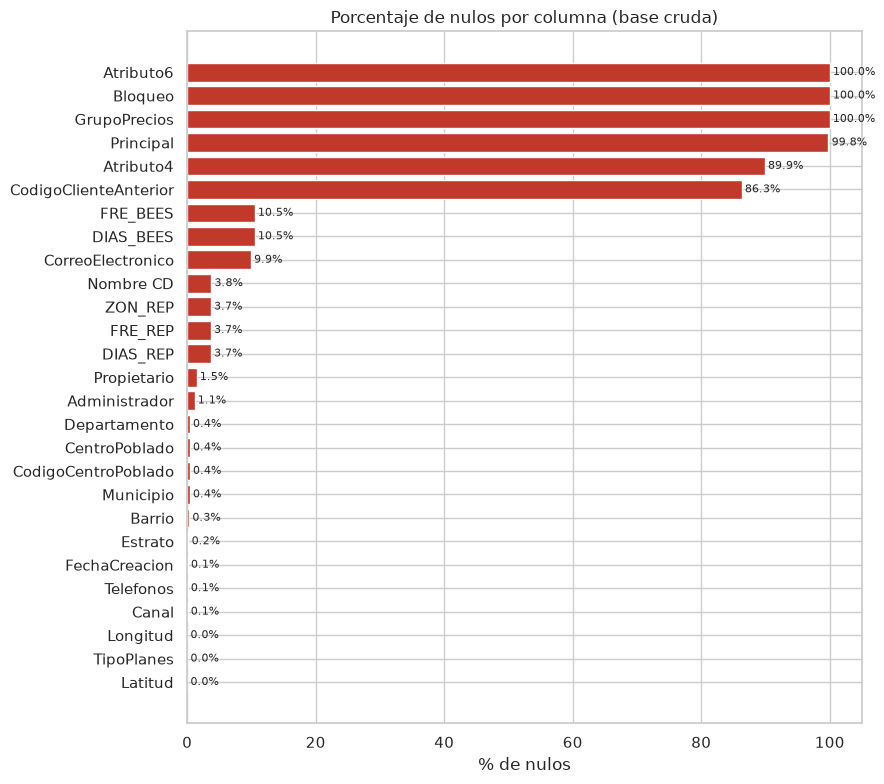

In [4]:
con_nulos = perfil[perfil.nulos > 0].sort_values("pct_nulos")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(con_nulos.index, con_nulos.pct_nulos, color="#c0392b")
ax.set_xlabel("% de nulos"); ax.set_title("Porcentaje de nulos por columna (base cruda)")
for i, v in enumerate(con_nulos.pct_nulos):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.show()

### 2.2 Columnas constantes y casi constantes

In [5]:
def dominancia(s):
    vc = s.value_counts(dropna=False, normalize=True)
    return vc.iloc[0]

dom = raw.apply(dominancia).sort_values(ascending=False)
dom[dom > 0.95].round(4).to_frame("proporcion_valor_dominante")

,proporcion_valor_dominante
Regional,1.0000
CodigoGerencia,1.0000
Gerencia,1.0000
Bloqueo,1.0000
Atributo6,1.0000
GrupoPrecios,0.9998
Principal,0.9980
Grupo,0.9980
Canal,0.9828
ClasificacionModelo,0.9668


### 2.3 Distribución de las principales variables categóricas

In [6]:
raw = raw[raw["Canal"].astype(str).str.strip() == "B2B"].copy()

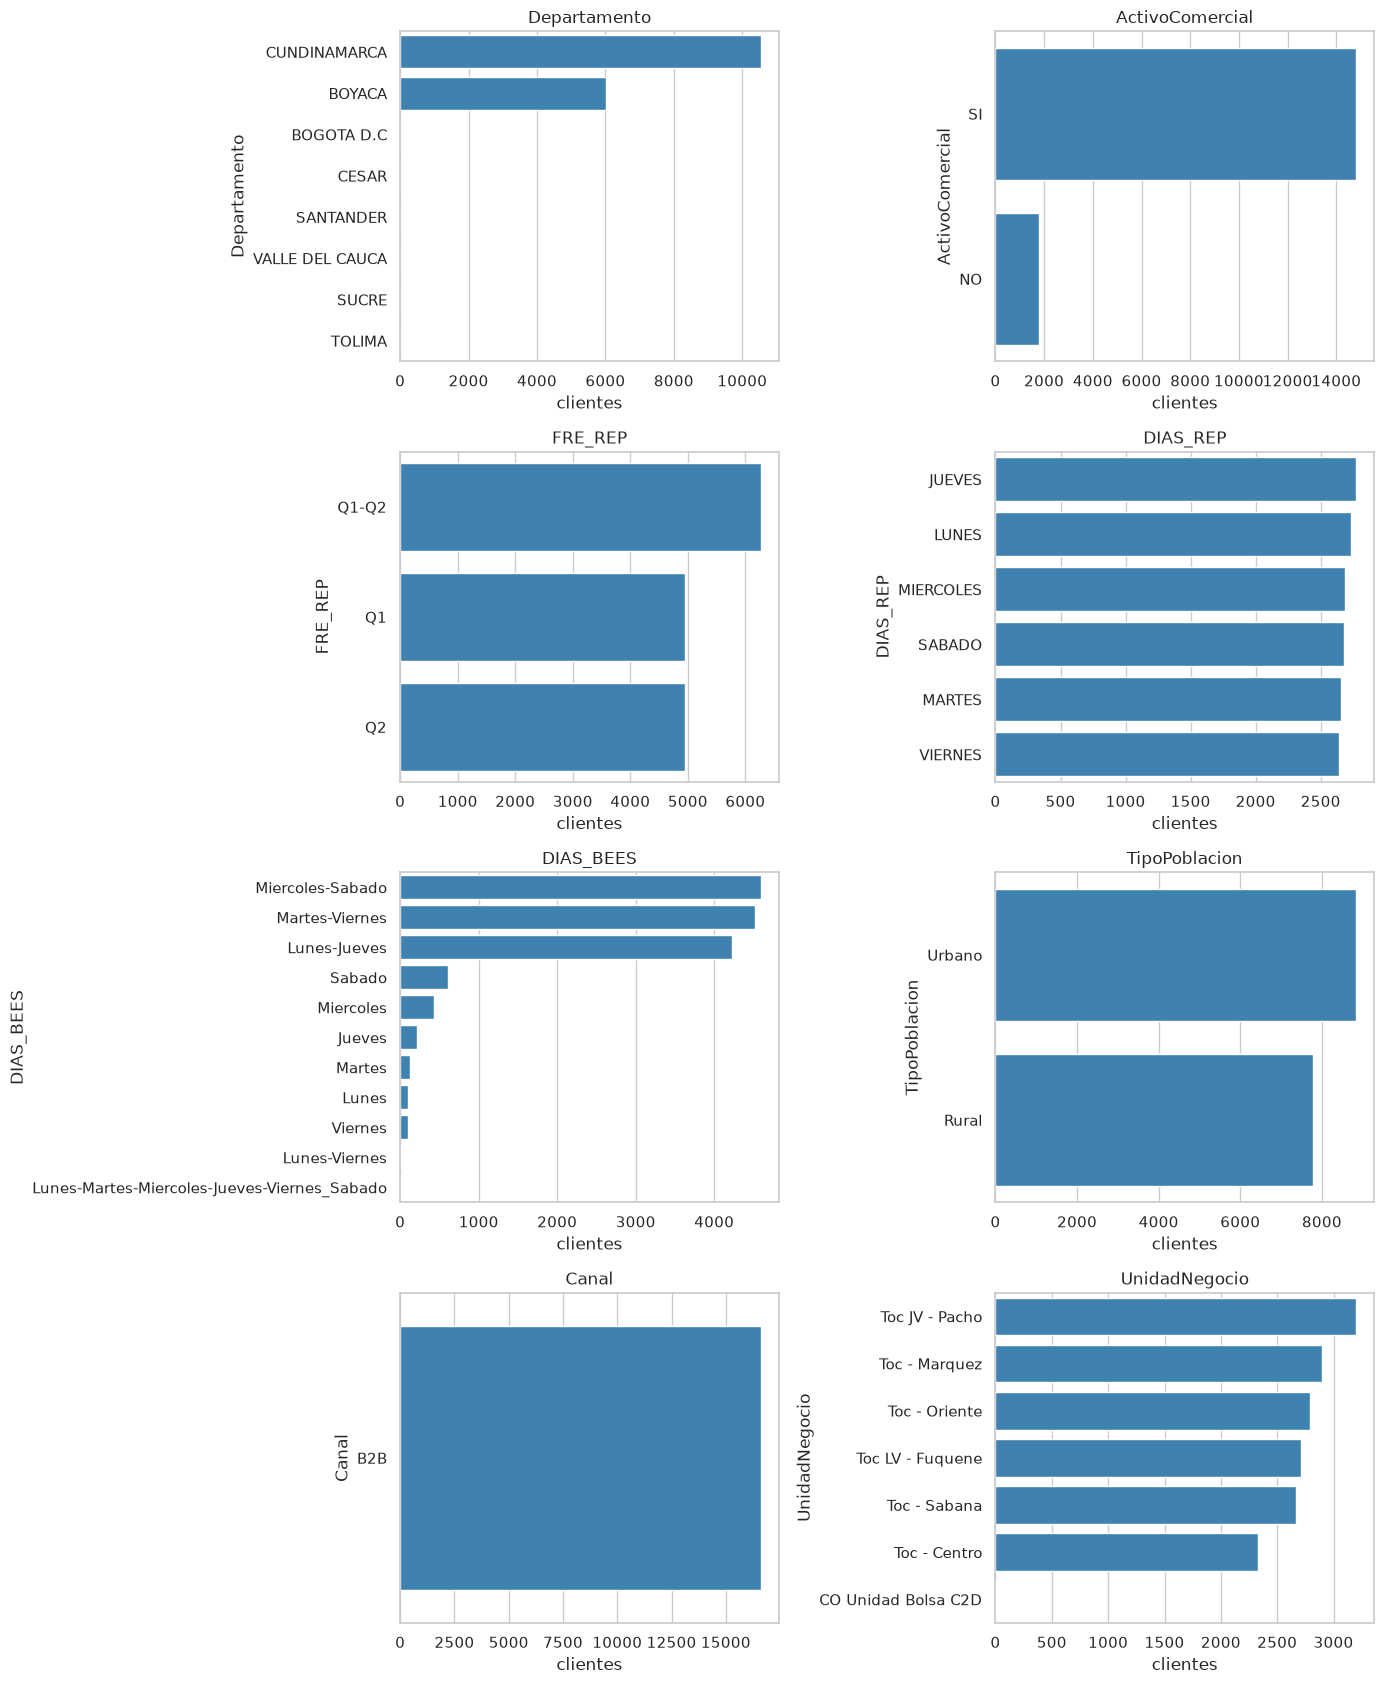

In [7]:
cats = ["Departamento", "ActivoComercial", "FRE_REP", "DIAS_REP", "DIAS_BEES", "TipoPoblacion", "Canal", "UnidadNegocio"]
fig, axes = plt.subplots(4, 2, figsize=(14, 17))
for ax, c in zip(axes.ravel(), cats):
    vc = raw[c].astype(str).str.strip().value_counts(dropna=False).head(12)
    sns.barplot(x=vc.values, y=vc.index, ax=ax, color="#2e86c1")
    ax.set_title(c); ax.set_xlabel("clientes")
plt.tight_layout(); plt.show()

### 2.4 Variables numéricas

,count,mean,std,min,25%,50%,75%,max
Estrato,16596.0,1.824717,0.684310,1.000000,1.000000,2.000000,2.00000,6.000000
EquiposFrio,16604.0,0.431462,0.747418,0.000000,0.000000,0.000000,1.00000,13.000000
Latitud,16603.0,5.156456,0.254709,3.445827,4.961224,5.096067,5.36678,6.267381
Longitud,16603.0,-73.748738,0.280339,-76.536229,-73.994440,-73.814800,-73.48490,-73.046554


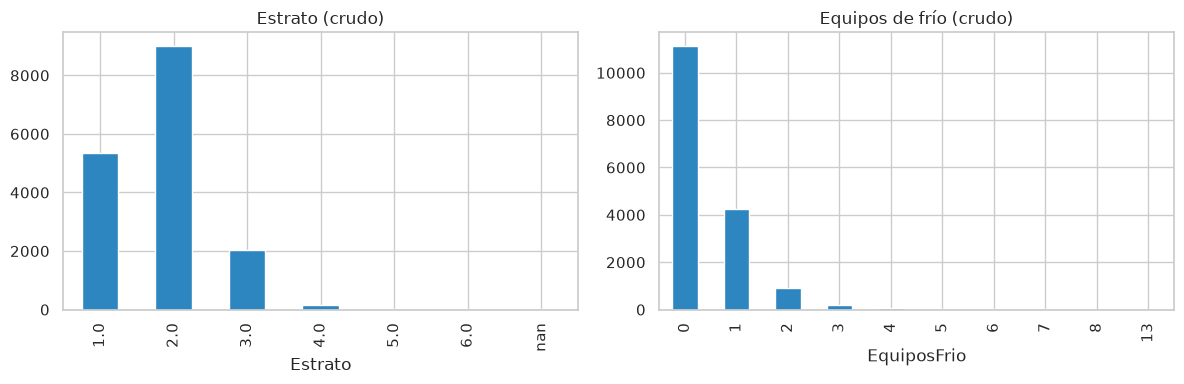

In [8]:
num_raw = ["Estrato", "EquiposFrio", "Latitud", "Longitud"]
display(raw[num_raw].describe().T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw.Estrato.value_counts(dropna=False).sort_index().plot.bar(ax=axes[0], color="#2e86c1", title="Estrato (crudo)")
raw.EquiposFrio.value_counts().sort_index().plot.bar(ax=axes[1], color="#2e86c1", title="Equipos de frío (crudo)")
plt.tight_layout(); plt.show()

### 2.5 Calidad de texto y de datos

In [9]:
# Caracteres de codificación dañados (aparecen como '�' por la exportación del archivo origen)
obj_cols = raw.select_dtypes(include=["object", "string"]).columns
dañadas = {c: int(raw[c].astype(str).str.contains("\ufffd").sum()) for c in obj_cols}
dañadas = {k: v for k, v in dañadas.items() if v > 0}
print("Columnas con caracteres dañados (�):", dañadas)
print("\nValores de ABC con apóstrofe inicial:", int(raw.ABC.astype(str).str.startswith("'").sum()))
print("Identificación con valores atípicamente grandes (>1e10):", int((raw.Identificacion > 1e10).sum()))
print("Filas con Latitud/Longitud nulas:", int(raw.Latitud.isna().sum()))

Columnas con caracteres dañados (�): {'Cliente': 1326, 'Propietario': 2492, 'Administrador': 2493, 'Barrio': 639, 'Direccion': 478, 'Municipio': 31, 'SubCanal': 1, 'ActividadEconomica': 66, 'Supervisor': 2328}

Valores de ABC con apóstrofe inicial: 182
Identificación con valores atípicamente grandes (>1e10): 0
Filas con Latitud/Longitud nulas: 1


## 3. Limpieza de datos
Se trabaja sobre una copia (`df`) y se va guardando un **embudo** con el número de filas tras cada paso.

In [10]:
df = raw.copy()
embudo = [("Base cruda", n_total), ("Solo canal B2B", len(df))]

# Limpieza básica de texto: quitar espacios sobrantes (las columnas vienen con espacios a la derecha)
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].astype("string").str.strip()
df = df.replace({"": pd.NA})

# ABC con apóstrofe inicial ("'04" -> "04")
df["ABC"] = df["ABC"].str.lstrip("'")
df["ABC_NABS"] = df["ABC_NABS"].str.lstrip("'")

def sin_tildes(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return s

def norm_txt(s):
    """Mayúsculas, sin tildes ni caracteres dañados; conserva letras, números y espacios."""
    if pd.isna(s):
        return ""
    s = str(s).replace("\ufffd", "")
    s = sin_tildes(s).upper()
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9 ]", " ", s)).strip()

# Se normalizan los nombres de municipio / actividad (el '�' no es recuperable, se elimina)
for c in ["Municipio", "CentroPoblado", "ActividadEconomica", "SubCanal", "Departamento", "Barrio"]:
    df[c] = df[c].map(lambda x: norm_txt(x) if pd.notna(x) else pd.NA).astype("string")
print("Texto normalizado.")

# --- Valores centinela en Supervisor: '--' -> 'SIN_ASESOR' -------------------
# Los 7 registros con '--' pertenecen a la "Unidad Bolsa C2D" (inactivos, 0 visitas).
# Se renombra a 'SIN_ASESOR' para no dejar un centinela crudo que rompa groupby/estratificacion.
df["Supervisor"] = df["Supervisor"].replace({"--": "SIN_ASESOR"})
print("Supervisor centinela:", (df["Supervisor"] == "SIN_ASESOR").sum(), "registros renombrados")

Texto normalizado.
Supervisor centinela: 8 registros renombrados


### 3.1 Geografía: imputar `Departamento`/`Municipio` nulos y filtrar a **Boyacá y Cundinamarca**
Hay 40 clientes sin departamento ni municipio. Antes de filtrar se **imputan** usando el vecino más cercano por coordenadas (Latitud/Longitud); si el cliente no tiene coordenadas, se **geocodifica su dirección** para obtenerlas y se repite el proceso. Así no se descartan clientes válidos solo por tener la geografía vacía

In [11]:
!pip install geopy -q

import re
import numpy as np
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors

COL_DIR = "Direccion"     # <-- ajusta al nombre real de tu columna de dirección
MAX_DIST_GRADOS = 0.5     # ~55 km: si el punto geocodificado queda más lejos de cualquier cliente conocido, se descarta

# ------------------------------------------------------------------
# 1) Diagnóstico
# ------------------------------------------------------------------
conocido = df.Municipio.notna() & df.Departamento.notna() & df.Latitud.notna() & df.Longitud.notna()
faltan_geo = df.Departamento.isna() | df.Municipio.isna()
print("Clientes con geografía incompleta:", int(faltan_geo.sum()))

# ------------------------------------------------------------------
# 2) Vecino más cercano (1-NN) por coordenadas
# ------------------------------------------------------------------
def imputar_por_coordenadas(df, conocido):
    faltan = df.Departamento.isna() | df.Municipio.isna()
    con_coord = faltan & df.Latitud.notna() & df.Longitud.notna()
    if not con_coord.any():
        return 0
    X = df.loc[conocido, ["Latitud", "Longitud"]].values
    nn = NearestNeighbors(n_neighbors=1).fit(X)
    for col in ["Departamento", "Municipio"]:
        m = con_coord & df[col].isna()
        if not m.any():
            continue
        Xq = df.loc[m, ["Latitud", "Longitud"]].values
        dist, _ = nn.kneighbors(Xq)
        knn = KNeighborsClassifier(n_neighbors=1).fit(X, df.loc[conocido, col].astype(str))
        pred = pd.Series(knn.predict(Xq), index=df.index[m])
        pred[dist.ravel() > MAX_DIST_GRADOS] = np.nan   # demasiado lejos: no se confía
        df.loc[m, col] = pred
    return int(con_coord.sum())

imputar_por_coordenadas(df, conocido)

# ------------------------------------------------------------------
# 3) Respaldo: geocodificar la DIRECCIÓN (reemplaza la moda por ZON_REP)
# ------------------------------------------------------------------
ABREV = {r"\bCL\b": "Calle", r"\bCLL\b": "Calle", r"\bKR\b": "Carrera", r"\bCR\b": "Carrera",
         r"\bCRA\b": "Carrera", r"\bAV\b": "Avenida", r"\bDG\b": "Diagonal",
         r"\bTV\b": "Transversal", r"\bMZ\b": "Manzana"}

def limpiar_direccion(d):
    d = str(d).upper().strip()
    d = re.sub(r"\b(APTO|APT|INT|INTERIOR|LOCAL|LC|OF|OFICINA|PISO|BODEGA)\b.*$", "", d)  # quita detalles internos
    for patron, reemplazo in ABREV.items():
        d = re.sub(patron, reemplazo, d)
    return re.sub(r"\s+", " ", d).strip()

geolocator = Nominatim(user_agent="imputacion_geografia_colab")
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1, max_retries=2, error_wait_seconds=3)
_cache = {}

def geocodificar_fila(fila):
    """Devuelve (lat, lon) a partir de la dirección, usando municipio/departamento si existen como contexto."""
    if pd.isna(fila[COL_DIR]) or not str(fila[COL_DIR]).strip():
        return (np.nan, np.nan)
    partes = [limpiar_direccion(fila[COL_DIR])]
    for c in ["Municipio", "Departamento"]:
        if pd.notna(fila[c]):
            partes.append(str(fila[c]))
    consulta = ", ".join(partes) + ", Colombia"
    if consulta not in _cache:
        loc = geocode(consulta, country_codes="co")
        _cache[consulta] = (loc.latitude, loc.longitude) if loc else (np.nan, np.nan)
    return _cache[consulta]

pend = df[df.Departamento.isna() | df.Municipio.isna()]
print("Pendientes tras coordenadas:", len(pend))

if len(pend) == 0:
    print("No hay clientes pendientes: se omite la geocodificación por dirección.")
else:
    print("Geocodificando por dirección...")
    coords = pd.DataFrame([geocodificar_fila(f) for _, f in pend.iterrows()],
                          index=pend.index, columns=["_lat_dir", "_lon_dir"])

    # Solo se llenan coordenadas que estaban vacías; las originales no se tocan
    for orig, nueva in [("Latitud", "_lat_dir"), ("Longitud", "_lon_dir")]:
        m = df[orig].isna() & df.index.isin(coords.index)
        df.loc[m, orig] = coords.loc[df.index[m], nueva].values

    # Se repite el 1-NN con las coordenadas obtenidas desde la dirección
    imputar_por_coordenadas(df, conocido)

# ------------------------------------------------------------------
# 4) Resultado
# ------------------------------------------------------------------
sin_resolver = df.Departamento.isna() | df.Municipio.isna()
print("Geografía incompleta tras imputar:", int(sin_resolver.sum()))
if sin_resolver.any():
    display(df.loc[sin_resolver, [COL_DIR, "Departamento", "Municipio", "Latitud", "Longitud"]])

print("\nDepartamentos antes del filtro:")
display(df.Departamento.value_counts(dropna=False).to_frame("clientes"))

# ------------------------------------------------------------------
# 5) Filtro a Boyacá y Cundinamarca
# ------------------------------------------------------------------
DEPTOS_OK = ["BOYACA", "CUNDINAMARCA"]
fuera = df[~df.Departamento.isin(DEPTOS_OK)]
print(f"\nClientes eliminados (fuera de Boyacá/Cundinamarca o sin geografía): {len(fuera)}")
display(fuera.groupby("Departamento", dropna=False).size().to_frame("clientes"))

df = df[df.Departamento.isin(DEPTOS_OK)].copy()
embudo = [e for e in embudo if e[0] != "Solo Boyacá y Cundinamarca"]   # evita duplicar el paso si se re-ejecuta
embudo.append(("Solo Boyacá y Cundinamarca", len(df)))
assert set(df.Departamento.unique()) <= set(DEPTOS_OK), "Quedaron otros departamentos"
print("Filas restantes:", len(df))


/bin/bash: línea 1: pip: orden no encontrada


Clientes con geografía incompleta: 40
Pendientes tras coordenadas: 0
No hay clientes pendientes: se omite la geocodificación por dirección.
Geografía incompleta tras imputar: 0

Departamentos antes del filtro:


,clientes
Departamento,
CUNDINAMARCA,10565
BOYACA,6022
BOGOTA D C,8
CESAR,5
SANTANDER,1
VALLE DEL CAUCA,1
SUCRE,1
TOLIMA,1



Clientes eliminados (fuera de Boyacá/Cundinamarca o sin geografía): 17


,clientes
Departamento,
BOGOTA D C,8
CESAR,5
SANTANDER,1
SUCRE,1
TOLIMA,1
VALLE DEL CAUCA,1


Filas restantes: 16587


### 3.2 Duplicados (reglas de negocio)

1. **Código repetido + misma dirección** → falso positivo: se elimina el registro repetido.
2. **Misma cédula + misma dirección (dos o más códigos)** → es el mismo cliente con códigos duplicados:
   se deja **un solo código**. Prioridad para decidir cuál se conserva: (i) `ActivoComercial = SI`,
   (ii) tiene `DIAS_BEES`, (iii) tiene `DIAS_REP`, (iv) código más antiguo (menor).
3. **Misma cédula + direcciones diferentes** → es un cliente con **varias sucursales**: se conservan todas
   y se marcan con `es_sucursal` / `n_sucursales`.

Para comparar direcciones se normaliza el texto (mayúsculas, sin tildes, sin signos ni espacios) y se
incluye el municipio en la llave, para no confundir direcciones genéricas ("VEREDA", "AU 0") de municipios distintos.

In [12]:
def norm_dir(s):
    if pd.isna(s):
        return ""
    s = sin_tildes(str(s).replace("\ufffd", "")).upper()
    return re.sub(r"[^A-Z0-9]", "", s)

df["_dir_norm"] = df.Direccion.map(norm_dir)

# --- Regla 1: mismo CodigoCliente (y misma dirección)
d1 = df.duplicated(["CodigoCliente", "_dir_norm"], keep="first").sum()
d1_cod = df.CodigoCliente.duplicated().sum()
print(f"Regla 1 - CodigoCliente repetido: {d1_cod} | CodigoCliente + dirección repetidos: {d1}")
df = df.drop_duplicates(["CodigoCliente", "_dir_norm"], keep="first")
embudo.append(("Sin código repetido + misma dirección", len(df)))

# --- Regla 2: misma cédula + misma dirección (+ municipio) con 2+ códigos
llave = ["Identificacion", "_dir_norm", "Municipio"]
grupo_dup = df[df.duplicated(llave, keep=False)].copy()
print(f"\nRegla 2 - registros involucrados: {len(grupo_dup)} en {grupo_dup.groupby(llave).ngroups} clientes con códigos repetidos")
display(grupo_dup.sort_values(llave)[["CodigoCliente", "Cliente", "Identificacion", "Direccion", "Municipio",
                                      "ActivoComercial", "DIAS_BEES", "DIAS_REP", "FechaCreacion"]].head(20))

Regla 1 - CodigoCliente repetido: 0 | CodigoCliente + dirección repetidos: 0

Regla 2 - registros involucrados: 54 en 27 clientes con códigos repetidos


,CodigoCliente,Cliente,Identificacion,Direccion,Municipio,ActivoComercial,DIAS_BEES,DIAS_REP,FechaCreacion
3258,13852479,La Patrona,903929,KR 5 5-14,ZIPAQUIRA,NO,<NA>,VIERNES,24/02/2023
3260,13853213,La Patrona,903929,KR 5 5-14,ZIPAQUIRA,NO,<NA>,VIERNES,25/02/2023
7203,12550223,Deposito El Estanco,3069992,CL 8 BIS 2A-02,LA CALERA,SI,Miercoles-Sabado,MARTES,11/01/2020
11045,11288139,El Estanco,3069992,CL 8 BIS 2 A-02,LA CALERA,SI,Miercoles-Sabado,MARTES,29/09/2014
4490,13852486,Salsamentaria �lzate,9847698,CL 9 25-36,PACHO,NO,<NA>,VIERNES,24/02/2023
4491,13853226,Salsamentaria �lzate,9847698,CL 9 25-36,PACHO,NO,<NA>,VIERNES,25/02/2023
2678,13200543,Chechenic,23682119,KR 5 3-45,LA CAPILLA,SI,Miercoles-Sabado,SABADO,10/11/2021
2681,13202536,Se�ora Ana,23682119,KR 5 3-45,LA CAPILLA,SI,Miercoles-Sabado,SABADO,10/11/2021
6212,13829985,Las delicias,23995438,Principal Santa barbara Km 8,SABOYA,NO,<NA>,MARTES,31/01/2023
6213,13837621,Simon,23995438,Principal Santa barbara Km 8,SABOYA,SI,Lunes-Jueves,MIERCOLES,04/02/2023


In [13]:
# Ranking de prioridad para escoger qué código se conserva
df["_p_activo"] = (df.ActivoComercial == "SI").astype(int)
df["_p_bees"] = df.DIAS_BEES.notna().astype(int)
df["_p_rep"] = df.DIAS_REP.notna().astype(int)

df = df.sort_values(["_p_activo", "_p_bees", "_p_rep", "CodigoCliente"],
                    ascending=[False, False, False, True])
eliminados_r2 = df[df.duplicated(llave, keep="first")]
print("Códigos eliminados por Regla 2:", len(eliminados_r2))
df = df.drop_duplicates(llave, keep="first").sort_index()
df = df.drop(columns=["_p_activo", "_p_bees", "_p_rep"])
embudo.append(("Un solo código por cliente-dirección", len(df)))

# --- Regla 3: misma cédula, direcciones distintas = sucursales (se conservan y se marcan)
df["n_sucursales"] = df.groupby("Identificacion")["CodigoCliente"].transform("count")
df["es_sucursal"] = (df.n_sucursales > 1).astype(int)
print(f"\nClientes (cédulas) con varias sucursales: {df.loc[df.es_sucursal == 1, 'Identificacion'].nunique()}"
      f" | registros que son sucursales: {int(df.es_sucursal.sum())}")
print("Distribución del número de sucursales por cédula:")
display(df.drop_duplicates("Identificacion").n_sucursales.value_counts().sort_index().to_frame("cedulas"))

# Verificación final
assert df.CodigoCliente.is_unique
assert not df.duplicated(llave).any()
print("OK: no quedan códigos repetidos ni cliente-dirección duplicados.")

Códigos eliminados por Regla 2: 27



Clientes (cédulas) con varias sucursales: 287 | registros que son sucursales: 594
Distribución del número de sucursales por cédula:


,cedulas
n_sucursales,
1,15966
2,269
3,16
4,2


OK: no quedan códigos repetidos ni cliente-dirección duplicados.


### 3.3 Nulos

Criterio por tipo de columna:

| Columna | Tratamiento |
|---|---|
| `Bloqueo`, `Atributo6`, `GrupoPrecios`, `Principal` | ≥ 99,8 % nulos → se eliminan (sección 3.4) |
| `ZON_REP` | se completa con `CodigoZona_Principal` (son la misma zona; la segunda no tiene nulos) |
| `FRE_REP`, `DIAS_REP`, `FRE_BEES`, `DIAS_BEES` | nulo **estructural** (cliente sin día/frecuencia asignada) → `SIN_ASIGNAR` + bandera. No se imputan porque inventar un día de visita distorsionaría el rutero y estos nulos son justamente los candidatos a *falso inactivo* |
| `Estrato` | moda por municipio y tipo de población |
| `Barrio` | `SIN_DATO` |
| `Canal` | moda (B2B) |
| `FechaCreacion` | mediana de la fecha dentro de la zona (solo para calcular antigüedad) |
| `Latitud`, `Longitud` | mediana del municipio |
| `CodigoClienteAnterior`, `Atributo4` | se convierten en banderas (`tiene_codigo_anterior`, `tiene_atributo4`) |
| `Nombre CD` | se conserva: se imputa con el nombre modal por `Cod CD`; el respaldo `CD + código` cubre los códigos sin nombre (AV61) |
| `TipoPlanes` | `SIN_DATO` |
| `CentroPoblado` | se completa con el `Municipio` |

In [14]:
nulos_antes = df.isna().sum()
nulos_antes = nulos_antes[nulos_antes > 0].to_frame("nulos_antes")

# --- Zona: completar ZON_REP con la zona principal
df["ZON_REP"] = df.ZON_REP.fillna(df.CodigoZona_Principal)

# --- Banderas a partir de columnas con muchos nulos
df["tiene_codigo_anterior"] = df.CodigoClienteAnterior.notna().astype(int)
df["tiene_atributo4"] = df.Atributo4.notna().astype(int)

# --- Nulos estructurales de visita: bandera + SIN_ASIGNAR
df["sin_dias_rep"] = df.DIAS_REP.isna().astype(int)
df["sin_dias_bees"] = df.DIAS_BEES.isna().astype(int)
for c in ["FRE_REP", "DIAS_REP", "FRE_BEES", "DIAS_BEES"]:
    df[c] = df[c].fillna("SIN_ASIGNAR")

# Estandarizar nombre de días (DIAS_REP viene en mayúsculas, DIAS_BEES en minúsculas)
df["DIAS_REP"] = df.DIAS_REP.map(lambda x: x if x == "SIN_ASIGNAR" else sin_tildes(x).upper())
df["DIAS_BEES"] = df.DIAS_BEES.map(lambda x: x if x == "SIN_ASIGNAR" else sin_tildes(x).upper())

# --- Estrato: moda por municipio + tipo de población, con respaldo por municipio y global
def moda(s):
    m = s.dropna().mode()
    return m.iloc[0] if len(m) else np.nan

df["Estrato"] = df.Estrato.fillna(df.groupby(["Municipio", "TipoPoblacion"])["Estrato"].transform(moda))
df["Estrato"] = df.Estrato.fillna(df.groupby("Municipio")["Estrato"].transform(moda))
df["Estrato"] = df.Estrato.fillna(df.Estrato.mode().iloc[0])

# --- Categóricas
df["Barrio"] = df.Barrio.fillna("SIN_DATO")
df["TipoPlanes"] = df.TipoPlanes.fillna("SIN_DATO")
df["CentroPoblado"] = df.CentroPoblado.fillna(df.Municipio)   # el centro poblado equivale al casco municipal
df["Canal"] = df.Canal.fillna(df.Canal.mode().iloc[0])
df["Canal"] = df.Canal.str.upper()

# --- Nombre del CD: se conserva (imputada con el nombre modal por código) ------------------
# La columna se conserva para que los notebooks aguas abajo (ruteo y Monte Carlo) funcionen
# solo con esta base limpia, sin depender del archivo crudo baseplan22Marzo.xlsx.
_nombre_modal = (df.groupby("Cod CD")["Nombre CD"]
                   .agg(lambda s: s.dropna().mode().iloc[0] if len(s.dropna().mode()) else pd.NA))
df["Nombre CD"] = df["Nombre CD"].fillna(df["Cod CD"].map(_nombre_modal))
df["Nombre CD"] = df["Nombre CD"].fillna("CD " + df["Cod CD"].astype(str))   # respaldo p.ej. AV61
print("Nombre CD sin dato tras imputar:", int(df["Nombre CD"].isna().sum()))

# --- Coordenadas: mediana del municipio
for c in ["Latitud", "Longitud"]:
    df[c] = df[c].fillna(df.groupby("Municipio")[c].transform("median"))

# --- Fecha de creación -> datetime; nulos con la mediana de su zona
df["FechaCreacion"] = pd.to_datetime(df.FechaCreacion, format="%d/%m/%Y", errors="coerce")
mediana_zona = df.groupby("ZON_REP")["FechaCreacion"].transform(lambda s: s.dropna().median())
df["FechaCreacion"] = df.FechaCreacion.fillna(mediana_zona).fillna(df.FechaCreacion.median())

print("Nulos tratados (el resumen antes/después se muestra en la sección 3.4, junto con las columnas eliminadas).")

Nombre CD sin dato tras imputar: 0


Nulos tratados (el resumen antes/después se muestra en la sección 3.4, junto con las columnas eliminadas).


### 3.4 Eliminación de columnas no relevantes
Se eliminan columnas por alguna de estas razones: (a) casi vacías, (b) constantes, (c) duplicadas por otra
columna equivalente, (d) datos personales / de contacto sin valor analítico para el balanceo del rutero.

In [15]:
drop_map = {
    "Bloqueo": "100 % nulos",
    "Atributo6": "100 % nulos",
    "GrupoPrecios": "99,98 % nulos",
    "Principal": "99,8 % nulos (solo 33 registros)",
    "Regional": "constante (CO Centro)",
    "CodigoGerencia": "constante",
    "Gerencia": "constante",
    "Canal": "constante tras filtrar a B2B",
    "Grupo": "99,8 % un solo valor (RGDE)",
    "ClasificacionModelo": "96 % 'No Aplica' (casi constante)",
    "UniNegocio": "duplicada de UnidadNegocio (código vs nombre)",
    "CodigoZona_Principal": "duplicada de ZON_REP",
    "CodigoSubCanal": "código equivalente a SubCanal",
    "CodigoCentroPoblado": "código equivalente a CentroPoblado",
    "CodigoClienteAnterior": "convertida en bandera tiene_codigo_anterior",
    "Atributo4": "convertida en bandera tiene_atributo4",
    "Propietario": "dato personal sin valor analítico",
    "Administrador": "dato personal sin valor analítico",
    "Telefonos": "dato de contacto (además con valores corruptos)",
    "CorreoElectronico": "dato de contacto (10 % nulos)",
    "TelSupervisor": "dato de contacto",
}
cols_drop = [c for c in drop_map if c in df.columns]
display(pd.DataFrame({"columna": cols_drop, "motivo": [drop_map[c] for c in cols_drop]}))
df = df.drop(columns=cols_drop + ["_dir_norm"], errors="ignore")
print("Columnas restantes:", df.shape[1])

# Resumen de nulos: antes (tras filtro y duplicados) vs después del tratamiento
resumen_nulos = nulos_antes.join(df.isna().sum().rename("nulos_despues"), how="left")
resumen_nulos["accion"] = np.where(resumen_nulos.nulos_despues.isna(), "columna eliminada", "imputado / tratado")
resumen_nulos["nulos_despues"] = resumen_nulos.nulos_despues.fillna(0).astype(int)
display(resumen_nulos)

,columna,motivo
0,Bloqueo,100 % nulos
1,Atributo6,100 % nulos
2,GrupoPrecios,"99,98 % nulos"
3,Principal,"99,8 % nulos (solo 33 registros)"
4,Regional,constante (CO Centro)
5,CodigoGerencia,constante
6,Gerencia,constante
7,Canal,constante tras filtrar a B2B
8,Grupo,"99,8 % un solo valor (RGDE)"
9,ClasificacionModelo,96 % 'No Aplica' (casi constante)


Columnas restantes: 39


,nulos_antes,nulos_despues,accion
FRE_REP,430,0,imputado / tratado
DIAS_REP,430,0,imputado / tratado
ZON_REP,430,0,imputado / tratado
DIAS_BEES,1631,0,imputado / tratado
FRE_BEES,1631,0,imputado / tratado
FechaCreacion,11,0,imputado / tratado
Principal,16553,0,columna eliminada
CodigoClienteAnterior,14275,0,columna eliminada
Propietario,198,0,columna eliminada
Administrador,183,0,columna eliminada


### 3.5 Clasificación de la actividad económica
Se agrupan las ~60 actividades en **4 categorías** mediante reglas de texto ordenadas (la primera que coincide gana):

- **Bodegas**: mayoristas, distribuidores, representantes y "MY" (mayorista).
- **Entretenimiento**: bares, discotecas, licobares, billares, campos de tejo, canchas, eventos y entretenimiento.
- **Tiendas**: tiendas (social, de barrio, básica, especial), minimercados, supermercados, C-Store y licoreras.
- **Otros**: todo lo que no cae en las anteriores (restaurantes, cafeterías/panaderías, comida rápida, clientes nuevos, instituciones, etc.).

In [16]:
REGLAS = [
    ("Bodegas",         r"\bMY\b|MAYORIST|DISTRIBUIDOR|\bDIST\b|REPRESENTANTE"),
    ("Entretenimiento", r"\bBAR\b|LICOBAR|DISCOTECA|BILLAR|TEJO|CANCHA|ENTRET|EVENTOS"),
    ("Tiendas",         r"TIENDA|MINIMERCADO|MINIMCADO|SUPERMERCADO|^SUP\b|C STORE|LICORERA"),
]

def clasificar(act):
    a = norm_txt(act)
    for cat, patron in REGLAS:
        if re.search(patron, a):
            return cat
    return "Otros"

df["CategoriaActividad"] = df.ActividadEconomica.map(clasificar)

tabla = (df.groupby(["CategoriaActividad", "ActividadEconomica"]).size()
           .rename("clientes").reset_index().sort_values(["CategoriaActividad", "clientes"], ascending=[True, False]))
display(df.CategoriaActividad.value_counts().to_frame("clientes").assign(pct=lambda x: (x.clientes / x.clientes.sum() * 100).round(1)))
for cat in ["Bodegas", "Entretenimiento", "Tiendas", "Otros"]:
    print(f"\n== {cat} ==")
    print(", ".join(f"{a} ({n})" for a, n in tabla[tabla.CategoriaActividad == cat][["ActividadEconomica", "clientes"]].values))

,clientes,pct
CategoriaActividad,,
Tiendas,11432,69.0
Otros,3233,19.5
Entretenimiento,1532,9.3
Bodegas,363,2.2



== Bodegas ==
MAYORIST IND AGENCIA (153), MAYORISTA (84), MY CON DEPSITO (41), MY COMPLEMENTARIO (37), MY EVENTERO (16), MINI DISTRIBUIDOR (11), MY CON DISTRIBUCIN (10), DIST LOGSTICO (7), REPRESENTANTE (4)

== Entretenimiento ==
BAR TRADICIONAL (668), CAMPO DE TEJO (384), BILLAR (213), OTROS ENTRETENIM TO (102), BAR PREMIUM (40), CANCHA DE FUTBOL (25), ENTRET TO FAMILIAR (22), DISCOTECA (21), RESTAURANTE BAR (17), LICOBAR (15), BAR ROJO (11), ENTRETENI TO PREMIUM (5), DISCOTECA PREMIUM (4), EVENTOS (4), CANCHA SINTT FTBOL (1)

== Tiendas ==
TIENDA SOCIAL (5630), TIENDA DE BARRIO (2713), TIENDA BASICA (1600), MINIMERCADO MS (651), TIENDA ESPECIAL (467), LICORERA (287), MINIMERCADO BARRIO (69), TIENDA NABS (6), MINIMERCADO PREMIUM (3), LICORERA HIGH END (2), SUPERMERCADO MS (2), MINIMCADO GASOLINERA (1), SUP INDEPENDIENTE (1)

== Otros ==
CAFETERIA PANADERIA (1051), CLIENTE NUEVO (850), RESTAURANTE (605), VENTA HOGAR (316), COMIDA RAPIDA (161), RESTPOLLO ALA BRASAS (81), RESTAURANTE PR

### 3.6 Variables de visita: Q1 / Q2, `DIAS_REP`, `DIAS_BEES`
- **Q1** = días 1-15, **Q2** = día 16 al fin de mes, **Q1-Q2** = todo el mes.
- Con `FRE_REP` (frecuencia) y `DIAS_REP` (día de la semana) se cuentan cuántas veces cae ese día dentro del
  periodo del mes de referencia → `visitas_mes_rep`. Ej.: `Q1-Q2` + `LUNES` = todos los lunes del mes.
- `DIAS_BEES` lista los días de la semana en que el asesor visita (ej. `MIERCOLES-SABADO`); con `FRE_BEES` se obtiene
  `visitas_mes_bees` y `n_dias_bees` (días por semana).

In [17]:
DIAS = {"LUNES": 0, "MARTES": 1, "MIERCOLES": 2, "JUEVES": 3, "VIERNES": 4, "SABADO": 5, "DOMINGO": 6}
ultimo = calendar.monthrange(ANIO_REF, MES_REF)[1]

def fechas_periodo(frec):
    if frec == "Q1":
        rango = range(1, 16)
    elif frec == "Q2":
        rango = range(16, ultimo + 1)
    elif frec == "Q1-Q2":
        rango = range(1, ultimo + 1)
    else:
        return []
    return [pd.Timestamp(ANIO_REF, MES_REF, d) for d in rango]

def contar_visitas(frec, dias_txt):
    if frec not in ("Q1", "Q2", "Q1-Q2") or dias_txt == "SIN_ASIGNAR":
        return 0
    dias = {DIAS[d] for d in re.split(r"[-_]", dias_txt) if d in DIAS}
    return sum(1 for f in fechas_periodo(frec) if f.weekday() in dias)

df["visitas_mes_rep"] = [contar_visitas(f, d) for f, d in zip(df.FRE_REP, df.DIAS_REP)]
df["visitas_mes_bees"] = [contar_visitas(f, d) for f, d in zip(df.FRE_BEES, df.DIAS_BEES)]
df["n_dias_bees"] = df.DIAS_BEES.map(lambda x: 0 if x == "SIN_ASIGNAR" else len([d for d in re.split(r"[-_]", x) if d in DIAS]))
df["periodo_rep"] = df.FRE_REP.map({"Q1": "1ra quincena", "Q2": "2da quincena", "Q1-Q2": "Mes completo"}).fillna("Sin asignar")

# Antigüedad del cliente (años) a la fecha de la base
FECHA_BASE = pd.Timestamp(ANIO_REF, MES_REF, 22)
df["antiguedad_anios"] = ((FECHA_BASE - df.FechaCreacion).dt.days / 365.25).round(2)

# Variables binarias
df["activo"] = (df.ActivoComercial == "SI").astype(int)
df["es_rural"] = (df.TipoPoblacion.str.upper() == "RURAL").astype(int)

# Posibles falsos inactivos (preliminar): clientes marcados NO activo que sí tienen ruta/visita asignada,
# o activos sin día de visita BEES asignado
df["posible_falso_inactivo"] = (((df.activo == 0) & ((df.sin_dias_rep == 0) | (df.sin_dias_bees == 0))) |
                                ((df.activo == 1) & (df.sin_dias_bees == 1))).astype(int)

print("Ejemplo Q1-Q2 + LUNES en el mes de referencia:", contar_visitas("Q1-Q2", "LUNES"), "visitas")
print("Ejemplo Q1 + LUNES:", contar_visitas("Q1", "LUNES"), "visitas")
display(df[["FRE_REP", "DIAS_REP", "visitas_mes_rep", "DIAS_BEES", "n_dias_bees", "visitas_mes_bees"]].drop_duplicates().sort_values(["FRE_REP", "DIAS_REP"]).head(15))

Ejemplo Q1-Q2 + LUNES en el mes de referencia: 5 visitas
Ejemplo Q1 + LUNES: 2 visitas


,FRE_REP,DIAS_REP,visitas_mes_rep,DIAS_BEES,n_dias_bees,visitas_mes_bees
27,Q1,JUEVES,2,MARTES-VIERNES,2,9
111,Q1,JUEVES,2,LUNES-JUEVES,2,9
217,Q1,JUEVES,2,SIN_ASIGNAR,0,0
248,Q1,JUEVES,2,MIERCOLES,1,4
270,Q1,JUEVES,2,MIERCOLES-SABADO,2,8
1868,Q1,JUEVES,2,SABADO,1,4
1954,Q1,JUEVES,2,VIERNES,1,4
2470,Q1,JUEVES,2,JUEVES,1,4
4159,Q1,JUEVES,2,LUNES,1,5
4174,Q1,JUEVES,2,LUNES-VIERNES,2,9


In [18]:
embudo.append(("Base limpia final", len(df)))
print("Nulos restantes en la base limpia:", int(df.isna().sum().sum()))
df.info()

Nulos restantes en la base limpia: 0
<class 'pandas.DataFrame'>
Index: 16560 entries, 0 to 16893
Data columns (total 48 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   FRE_REP                 16560 non-null  string        
 1   DIAS_REP                16560 non-null  str           
 2   ZON_REP                 16560 non-null  string        
 3   DIAS_BEES               16560 non-null  str           
 4   FRE_BEES                16560 non-null  string        
 5   FechaCreacion           16560 non-null  datetime64[us]
 6   CodigoCliente           16560 non-null  int64         
 7   Cliente                 16560 non-null  string        
 8   UnidadNegocio           16560 non-null  string        
 9   Identificacion          16560 non-null  int64         
 10  CondicionPago           16560 non-null  string        
 11  Longitud                16560 non-null  float64       
 12  Latitud                 1

## 4. EDA sobre la base limpia

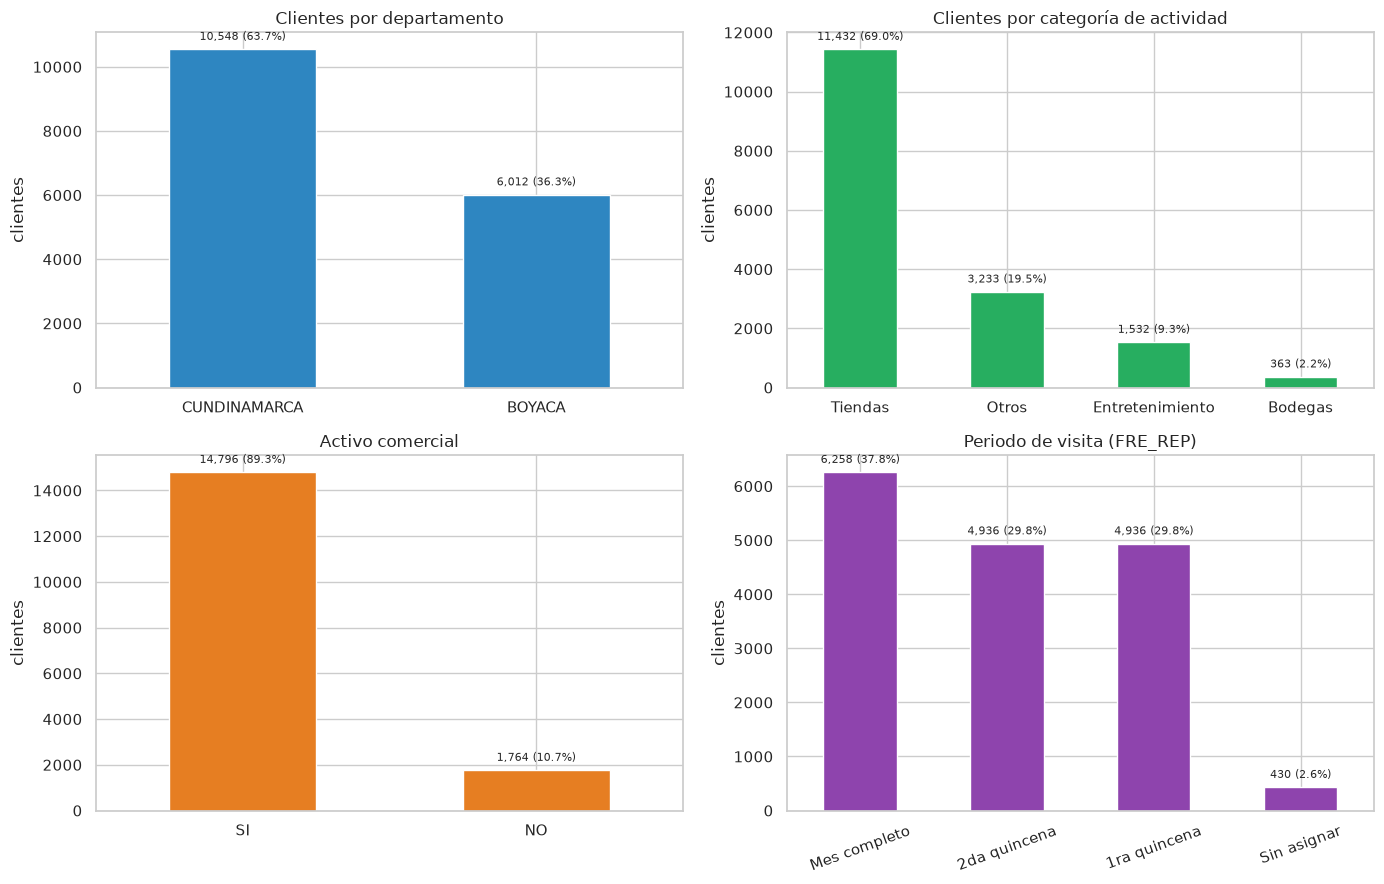

In [19]:
def poner_etiquetas(ax, total=None, pct=False):
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            if pct and total:
                label = f"{height:,.0f} ({height/total*100:.1f}%)"
            else:
                label = f"{height:,.0f}"
            ax.annotate(label,
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='center',
                        xytext=(0, 9),
                        textcoords='offset points',
                        fontsize=8)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
df.Departamento.value_counts().plot.bar(ax=axes[0, 0], color="#2e86c1", rot=0, title="Clientes por departamento")
df.CategoriaActividad.value_counts().plot.bar(ax=axes[0, 1], color="#27ae60", rot=0, title="Clientes por categoría de actividad")
df.ActivoComercial.value_counts().plot.bar(ax=axes[1, 0], color="#e67e22", rot=0, title="Activo comercial")
df.periodo_rep.value_counts().plot.bar(ax=axes[1, 1], color="#8e44ad", rot=20, title="Periodo de visita (FRE_REP)")

for ax in axes.ravel():
    poner_etiquetas(ax, total=len(df), pct=True)
    ax.set_xlabel(""); ax.set_ylabel("clientes")
plt.tight_layout(); plt.show()

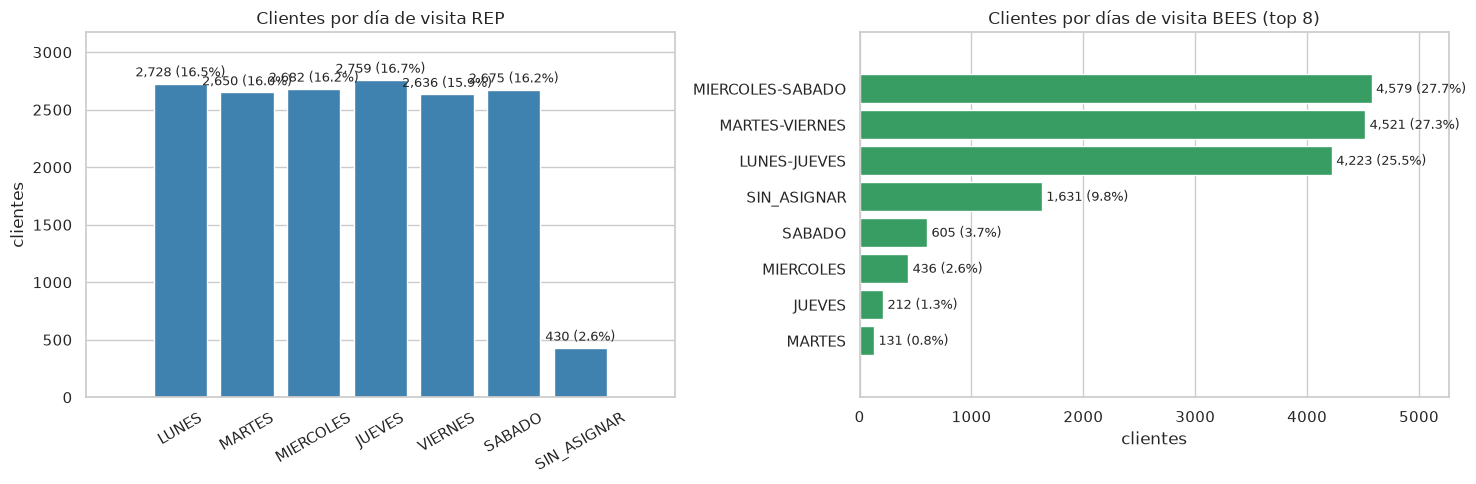

In [20]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
orden = ["LUNES", "MARTES", "MIERCOLES", "JUEVES", "VIERNES", "SABADO", "SIN_ASIGNAR"]

# --- Gráfico 1: día de visita REP (barras verticales)
sns.countplot(data=df, x="DIAS_REP", order=orden, ax=axes[0], color="#2e86c1")
axes[0].set_title("Clientes por día de visita REP")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_xlabel(""); axes[0].set_ylabel("clientes")

# --- Gráfico 2: días de visita BEES, top 8 (barras horizontales)
top_bees = df.DIAS_BEES.value_counts().head(8).index
sns.countplot(data=df[df.DIAS_BEES.isin(top_bees)], y="DIAS_BEES", order=top_bees, ax=axes[1], color="#27ae60")
axes[1].set_title("Clientes por días de visita BEES (top 8)")
axes[1].set_xlabel("clientes"); axes[1].set_ylabel("")

# --- Etiquetas con valor y porcentaje sobre el total de clientes
total = len(df)
for ax in axes:
    for cont in ax.containers:
        etiquetas = [f"{v:,.0f} ({v/total*100:.1f}%)" for v in cont.datavalues]
        ax.bar_label(cont, labels=etiquetas, padding=3, fontsize=9)
    ax.margins(x=0.15, y=0.15)   # espacio extra para que no se corten las etiquetas

plt.tight_layout(); plt.show()

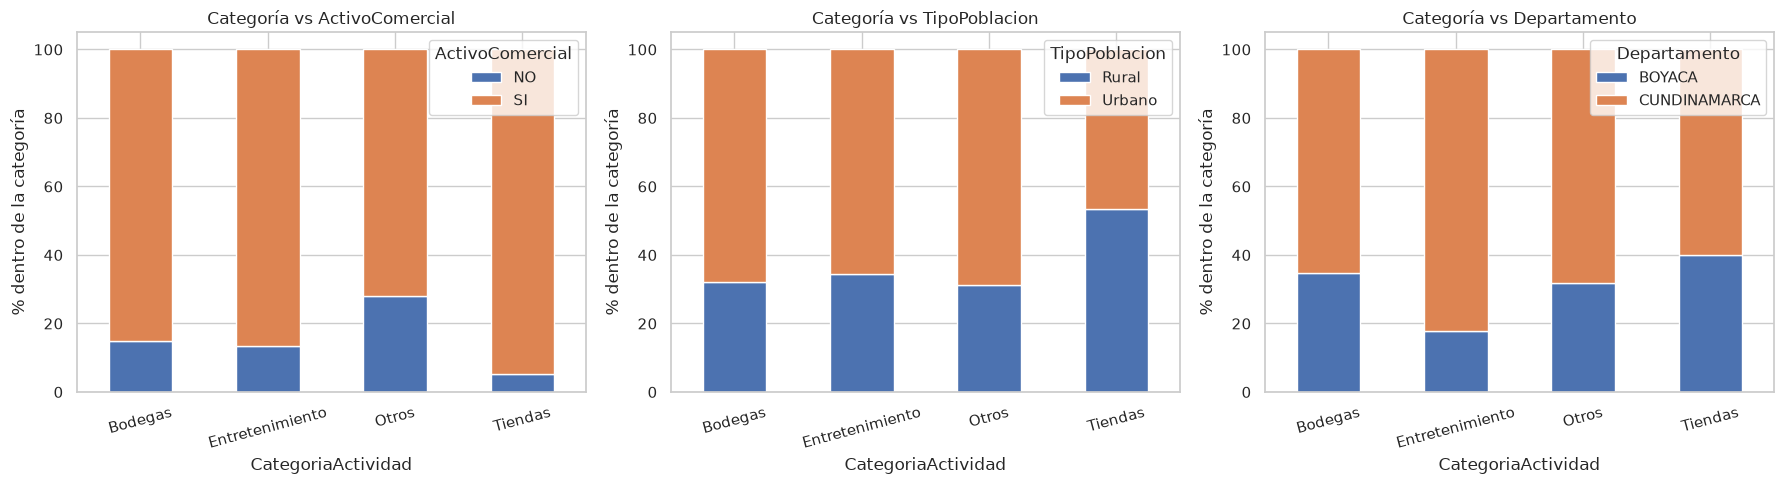

In [21]:
# Categoría de actividad vs. estado activo / tipo de población / departamento
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, ["ActivoComercial", "TipoPoblacion", "Departamento"]):
    pd.crosstab(df.CategoriaActividad, df[c], normalize="index").mul(100).plot.bar(stacked=True, ax=ax, rot=15)
    ax.set_ylabel("% dentro de la categoría"); ax.set_title(f"Categoría vs {c}")
plt.tight_layout(); plt.show()

,clientes,activos,visitas_mes_rep,visitas_dia_habil_aprox
ZON_REP,,,,
COM2DM,468,409,1011,38.9
COM2I9,460,376,992,38.2
COM310,448,381,968,37.2
COM2DK,439,393,948,36.5
COM2Y2,424,362,919,35.3
COM2DL,394,356,853,32.8
COM2Z6,365,344,1091,42.0
COM1B5,345,290,963,37.0
COM2D4,334,285,975,37.5


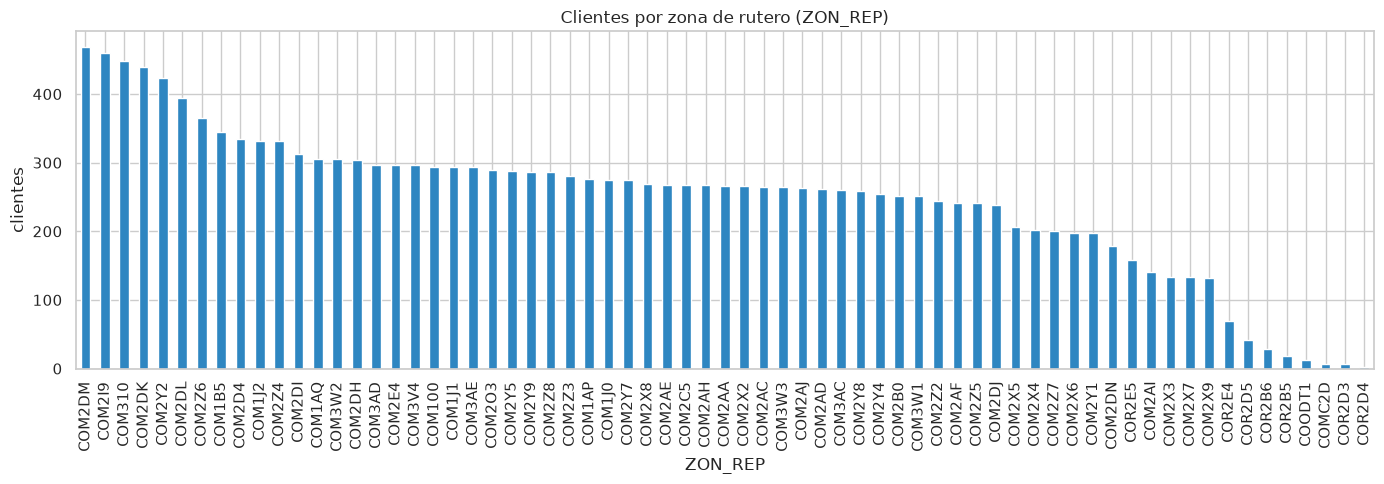

In [22]:
# Carga por zona de rutero (ZON_REP): clientes totales y visitas/mes. Referencia para el desbalance.
carga = (df.groupby("ZON_REP").agg(clientes=("CodigoCliente", "count"),
                                   activos=("activo", "sum"),
                                   visitas_mes_rep=("visitas_mes_rep", "sum"))
           .sort_values("clientes", ascending=False))
carga["visitas_dia_habil_aprox"] = (carga.visitas_mes_rep / 26).round(1)   # ~26 días hábiles (lun-sáb)
display(carga.head(15))

fig, ax = plt.subplots(figsize=(14, 5))
carga.clientes.plot.bar(ax=ax, color="#2e86c1")
ax.set_title("Clientes por zona de rutero (ZON_REP)"); ax.set_ylabel("clientes")
plt.tight_layout(); plt.show()

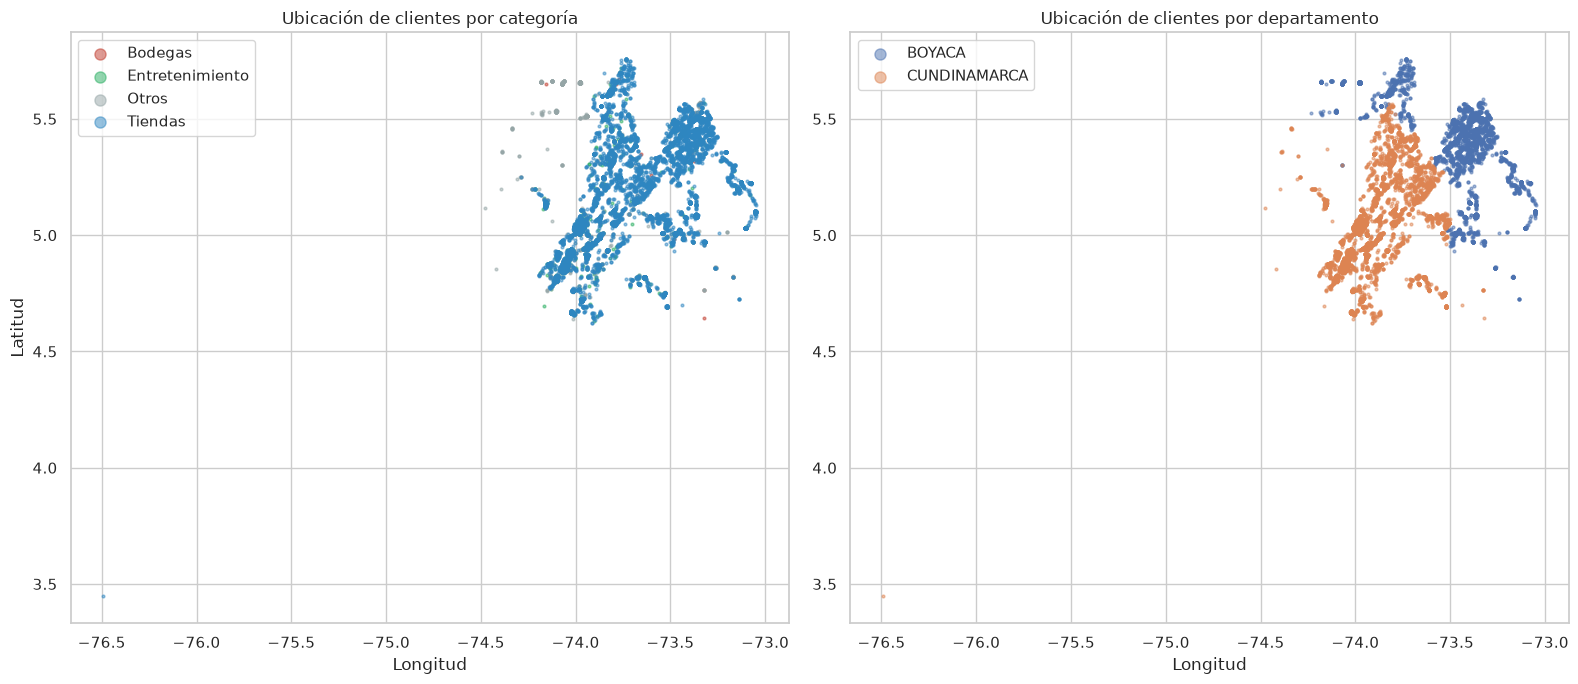

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
paleta = {"Tiendas": "#2e86c1", "Bodegas": "#c0392b", "Entretenimiento": "#27ae60", "Otros": "#95a5a6"}
for cat, g in df.groupby("CategoriaActividad"):
    axes[0].scatter(g.Longitud, g.Latitud, s=4, alpha=.5, label=cat, color=paleta[cat])
axes[0].set_title("Ubicación de clientes por categoría"); axes[0].set_xlabel("Longitud"); axes[0].set_ylabel("Latitud")
axes[0].legend(markerscale=4)
for dep, g in df.groupby("Departamento"):
    axes[1].scatter(g.Longitud, g.Latitud, s=4, alpha=.5, label=dep)
axes[1].set_title("Ubicación de clientes por departamento"); axes[1].set_xlabel("Longitud"); axes[1].legend(markerscale=4)
plt.tight_layout(); plt.show()

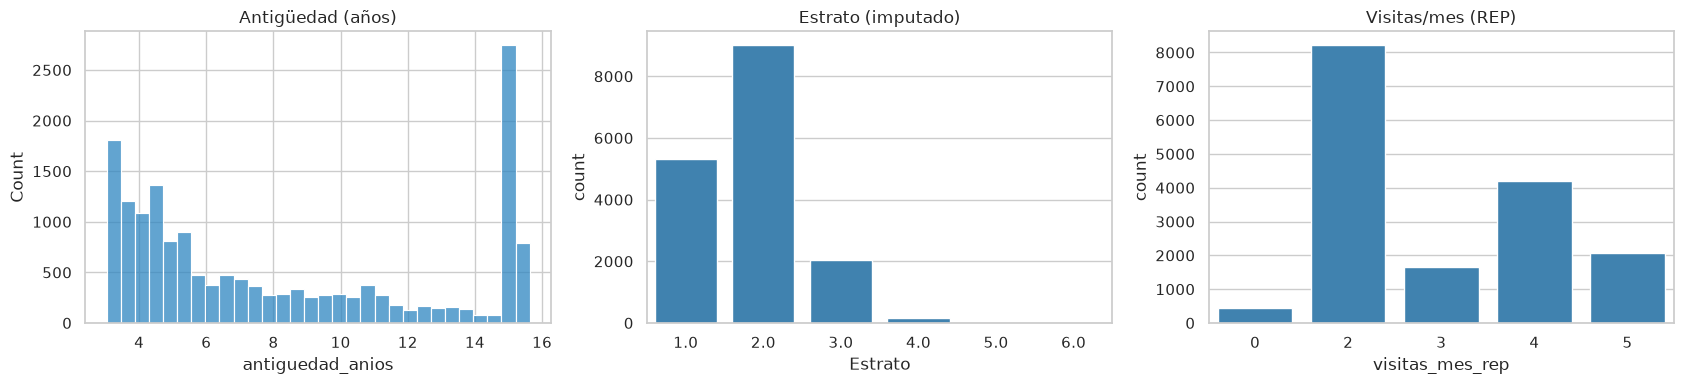

Posibles falsos inactivos (criterio preliminar): 2308


sin_dias_bees,0,1,All
ActivoComercial,,,
NO,938,826,1764
SI,13991,805,14796
All,14929,1631,16560


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(df.antiguedad_anios, bins=30, ax=axes[0], color="#2e86c1"); axes[0].set_title("Antigüedad (años)")
sns.countplot(x="Estrato", data=df, ax=axes[1], color="#2e86c1"); axes[1].set_title("Estrato (imputado)")
sns.countplot(x="visitas_mes_rep", data=df, ax=axes[2], color="#2e86c1"); axes[2].set_title("Visitas/mes (REP)")
plt.tight_layout(); plt.show()

print("Posibles falsos inactivos (criterio preliminar):", int(df.posible_falso_inactivo.sum()))
pd.crosstab(df.ActivoComercial, [df.sin_dias_bees], margins=True, rownames=["ActivoComercial"], colnames=["sin_dias_bees"])

## 5. Matriz de correlación
### 5.1 Variables numéricas — Pearson

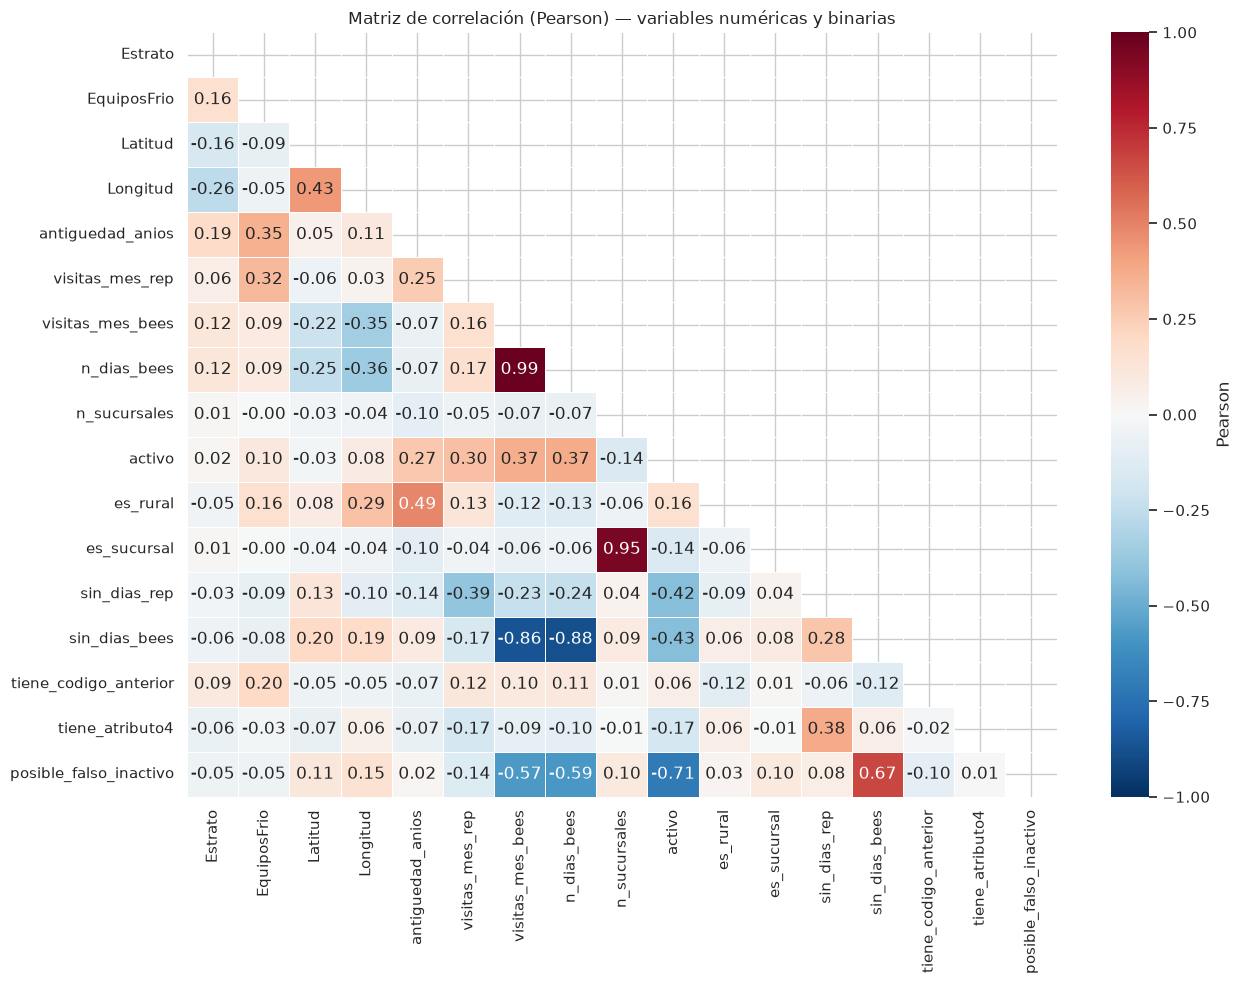

In [25]:
num_cols = ["Estrato", "EquiposFrio", "Latitud", "Longitud", "antiguedad_anios", "visitas_mes_rep",
            "visitas_mes_bees", "n_dias_bees", "n_sucursales", "activo", "es_rural", "es_sucursal",
            "sin_dias_rep", "sin_dias_bees", "tiene_codigo_anterior", "tiene_atributo4", "posible_falso_inactivo"]
corr = df[num_cols].corr(method="pearson")

plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.4, cbar_kws={"label": "Pearson"})
plt.title("Matriz de correlación (Pearson) — variables numéricas y binarias")
plt.tight_layout(); plt.show()

In [26]:
# Pares con correlación absoluta alta (>= 0.5), sin duplicados
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("correlacion").reset_index().rename(columns={"level_0": "var_1", "level_1": "var_2"}))
pares["abs"] = pares.correlacion.abs()
pares[pares["abs"] >= 0.5].sort_values("abs", ascending=False).drop(columns="abs").round(3)

,var_1,var_2,correlacion
109,visitas_mes_bees,n_dias_bees,0.988
147,n_sucursales,es_sucursal,0.952
132,n_dias_bees,sin_dias_bees,-0.882
115,visitas_mes_bees,sin_dias_bees,-0.864
169,activo,posible_falso_inactivo,-0.711
237,sin_dias_bees,posible_falso_inactivo,0.669
135,n_dias_bees,posible_falso_inactivo,-0.586
118,visitas_mes_bees,posible_falso_inactivo,-0.574


### 5.2 Variables categóricas — Cramér's V
Para variables nominales no aplica Pearson; se usa **Cramér's V** (0 = sin asociación, 1 = asociación perfecta),
con corrección de sesgo.

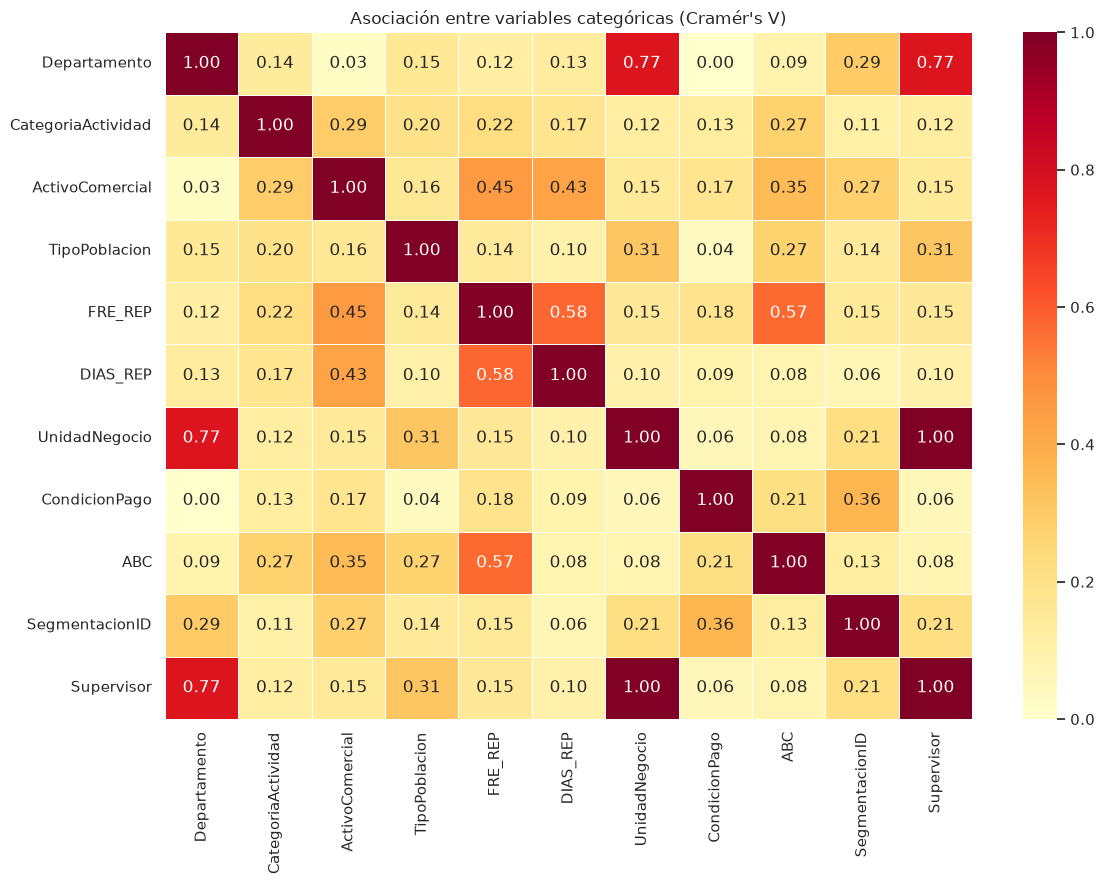

In [27]:
def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum()
    phi2 = chi2 / n
    r, k = tabla.shape
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    return np.sqrt(phi2corr / max(1e-12, min(kcorr - 1, rcorr - 1)))

cat_cols = ["Departamento", "CategoriaActividad", "ActivoComercial", "TipoPoblacion", "FRE_REP", "DIAS_REP",
            "UnidadNegocio", "CondicionPago", "ABC", "SegmentacionID", "Supervisor"]
cv = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)
for a in cat_cols:
    for b in cat_cols:
        cv.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])

plt.figure(figsize=(12, 9))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, linewidths=.4)
plt.title("Asociación entre variables categóricas (Cramér's V)")
plt.tight_layout(); plt.show()

### 5.3 Relación entre variables numéricas y la categoría de actividad (razón de correlación η)

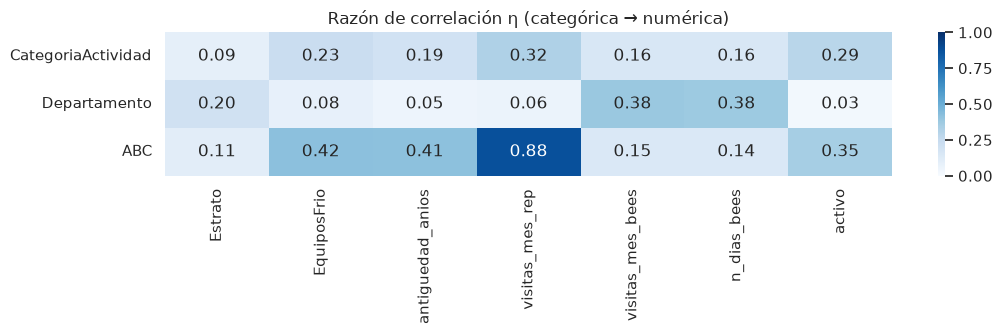

In [28]:
def eta_cuadrado(cat, num):
    medias = num.groupby(cat).transform("mean")
    ss_between = ((medias - num.mean()) ** 2).sum()
    ss_total = ((num - num.mean()) ** 2).sum()
    return np.sqrt(ss_between / ss_total) if ss_total else np.nan

num_eta = ["Estrato", "EquiposFrio", "antiguedad_anios", "visitas_mes_rep", "visitas_mes_bees", "n_dias_bees", "activo"]
eta = pd.DataFrame({c: [eta_cuadrado(df[cat], df[c]) for cat in ["CategoriaActividad", "Departamento", "ABC"]] for c in num_eta},
                   index=["CategoriaActividad", "Departamento", "ABC"])
plt.figure(figsize=(11, 3.5))
sns.heatmap(eta, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Razón de correlación η (categórica → numérica)")
plt.tight_layout(); plt.show()

## 6. Exportación y resumen del embudo de limpieza

,paso,filas,eliminadas_en_el_paso
0,Base cruda,16894,0
1,Solo canal B2B,16604,290
2,Solo Boyacá y Cundinamarca,16587,17
3,Sin código repetido + misma dirección,16587,0
4,Un solo código por cliente-dirección,16560,27
5,Base limpia final,16560,0


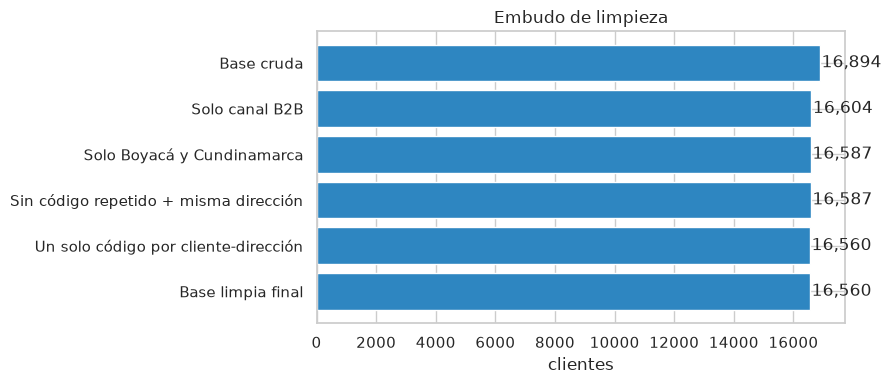

In [29]:
emb = pd.DataFrame(embudo, columns=["paso", "filas"])
emb["eliminadas_en_el_paso"] = (-emb.filas.diff()).fillna(0).astype(int)
display(emb)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(emb.paso[::-1], emb.filas[::-1], color="#2e86c1")
for i, v in enumerate(emb.filas[::-1]):
    ax.text(v + 50, i, f"{v:,}", va="center")
ax.set_title("Embudo de limpieza"); ax.set_xlabel("clientes")
plt.tight_layout(); plt.show()

In [30]:
SALIDA = "base_clientes_limpia.csv"
df.to_csv(SALIDA, index=False, encoding="utf-8-sig")
df.to_excel("base_clientes_limpia.xlsx", index=False)
print(f"Base limpia guardada: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print("Columnas finales:", list(df.columns))

Base limpia guardada: 16,560 filas x 48 columnas
Columnas finales: ['FRE_REP', 'DIAS_REP', 'ZON_REP', 'DIAS_BEES', 'FRE_BEES', 'FechaCreacion', 'CodigoCliente', 'Cliente', 'UnidadNegocio', 'Identificacion', 'CondicionPago', 'Longitud', 'Latitud', 'Estrato', 'Barrio', 'Direccion', 'Departamento', 'Municipio', 'CentroPoblado', 'ABC', 'ABC_NABS', 'SubCanal', 'Clase', 'ActividadEconomica', 'ActivoComercial', 'TipoPoblacion', 'SegmentacionID', 'TipoPlanes', 'EquiposFrio', 'ZonaTransporte', 'Supervisor', 'Cod CD', 'Nombre CD', 'n_sucursales', 'es_sucursal', 'tiene_codigo_anterior', 'tiene_atributo4', 'sin_dias_rep', 'sin_dias_bees', 'CategoriaActividad', 'visitas_mes_rep', 'visitas_mes_bees', 'n_dias_bees', 'periodo_rep', 'antiguedad_anios', 'activo', 'es_rural', 'posible_falso_inactivo']


## 7. Conclusiones y siguientes pasos
- La base queda con **un solo código por cliente-dirección**, solo con clientes de **Boyacá y Cundinamarca**, sin nulos y con las columnas irrelevantes eliminadas.
- Los clientes con la misma cédula y direcciones distintas se conservan como **sucursales** (`es_sucursal`, `n_sucursales`).
- Los nulos en `DIAS_REP` / `DIAS_BEES` se tratan como **sin visita asignada** y alimentan la bandera `posible_falso_inactivo`, base para el diagnóstico de falsos inactivos.
- Variables listas para el modelo de balanceo: `ZON_REP`, `CategoriaActividad`, `visitas_mes_rep`, `visitas_mes_bees`, `Latitud`/`Longitud`.
- **Siguiente paso:** agrupar geográficamente por asesor (clustering con restricción de 40-50 visitas/día) y secuenciar la visita según horarios por categoría (tiendas/bodegas temprano, entretenimiento en la tarde-noche).